
## **NAMA  : ANDI TRI LESTARI**
## **NIM   : H061241055**
## **KELAS : C**

## <center>**KECERDASAN ARTIFISIAL UNTUK GEOFISIKA**</center>
## <center>**Penerapan Prompt AI untuk Analisis dan Interpretasi Data Geofisika**</center>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True

## **Prompt 1 — Interpretasi Data Seismik Refleksi**

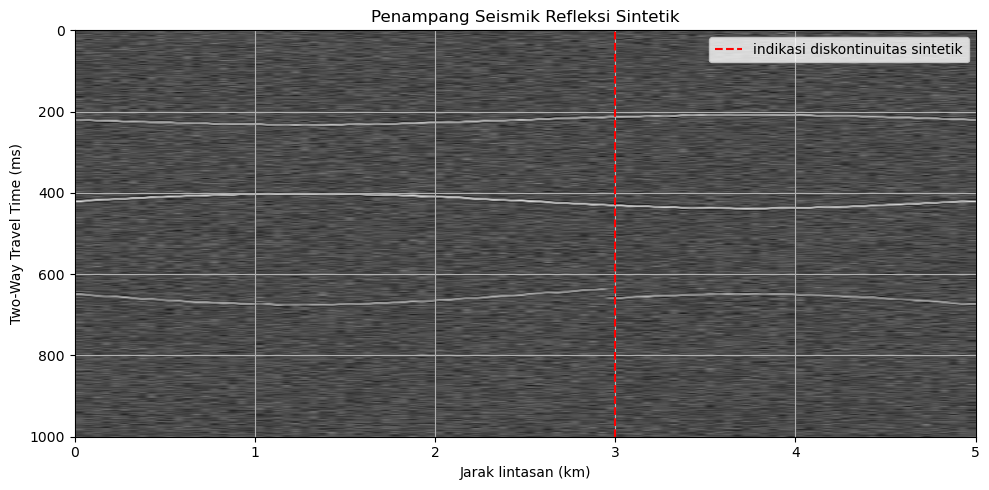

Tabel estimasi kedalaman (menggunakan kecepatan simulasi 2000 m/s):
Reflektor  TWT (ms)  Asumsi kecepatan (m/s)  Kedalaman perkiraan (m)
       R1       220                    2000                    220.0
       R2       420                    2000                    420.0
       R3       650                    2000                    650.0
Interpretasi awal: tiga reflektor sintetik terlihat; diskontinuitas sekitar 3 km
dibuat secara artifisial untuk mendemonstrasikan indikasi struktur, bukan sesar nyata.


In [2]:
# Radar/penampang sintetik: waktu TWT (ms) dan posisi trace.
n_time, n_trace = 500, 100
twt_ms = np.linspace(0, 1000, n_time)
x_km = np.linspace(0, 5, n_trace)
seismic = np.random.normal(0, 0.12, (n_time, n_trace))

# Reflektor berundulasi; amplitudo bertambah pada batas lapisan.
for t0, amp, curvature in [(220, 0.8, 12), (420, 1.0, -18), (650, 0.7, 25)]:
    for j, x in enumerate(x_km):
        center = t0 + curvature * np.sin(2*np.pi*x/5)
        idx = np.argmin(np.abs(twt_ms-center))
        if 1 <= idx < n_time-2:
            wavelet = np.array([-0.25, 0.65, 1.0, 0.65, -0.25]) * amp
            seismic[idx-2:idx+3, j] += wavelet

# Gangguan sintetik menyerupai diskontinuitas sesar pada posisi x sekitar 3 km.
fault_trace = np.argmin(np.abs(x_km-3.0))
seismic[260:360, fault_trace:] = np.roll(seismic[260:360, fault_trace:], 12, axis=0)

fig, ax = plt.subplots()
im = ax.imshow(seismic, cmap="gray", aspect="auto",
               extent=[x_km.min(), x_km.max(), twt_ms.max(), twt_ms.min()])
ax.axvline(3.0, color="red", linestyle="--", label="indikasi diskontinuitas sintetik")
ax.set(title="Penampang Seismik Refleksi Sintetik", xlabel="Jarak lintasan (km)",
       ylabel="Two-Way Travel Time (ms)")
ax.legend()
plt.tight_layout()
plt.show()

# Kedalaman perkiraan hanya dihitung bila kecepatan tersedia.
velocity_m_s = 2000
selected_twt_ms = np.array([220, 420, 650])
depth_m = velocity_m_s * (selected_twt_ms/1000) / 2
seismic_table = pd.DataFrame({
    "Reflektor": ["R1", "R2", "R3"],
    "TWT (ms)": selected_twt_ms,
    "Asumsi kecepatan (m/s)": velocity_m_s,
    "Kedalaman perkiraan (m)": depth_m
})
print("Tabel estimasi kedalaman (menggunakan kecepatan simulasi 2000 m/s):")
print(seismic_table.to_string(index=False))
print("Interpretasi awal: tiga reflektor sintetik terlihat; diskontinuitas sekitar 3 km")
print("dibuat secara artifisial untuk mendemonstrasikan indikasi struktur, bukan sesar nyata.")

## **Prompt 2 — Analisis Data Geomagnetik**

Jumlah titik/grid: 2880
Rentang anomali sintetik: -79.1 hingga 123.3 nT
Rata-rata anomali: 0.1 nT


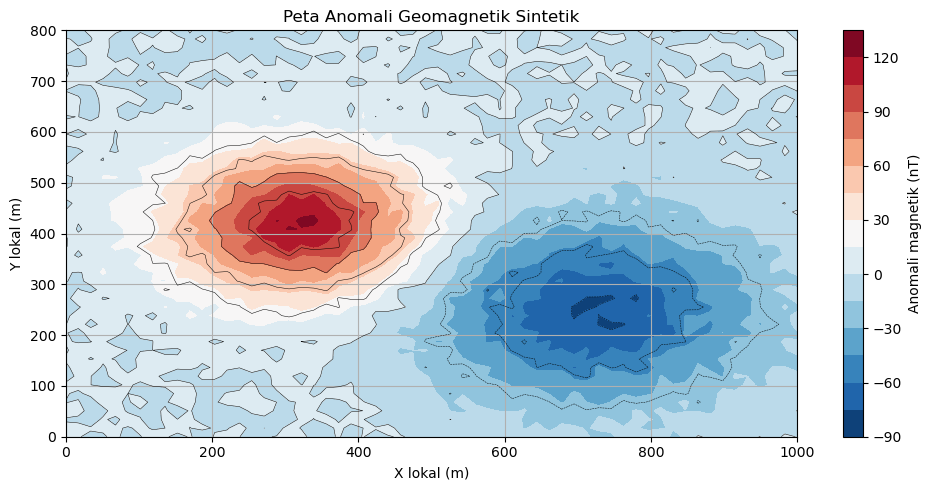

Interpretasi awal: anomali positif berpusat kira-kira di (320 m, 420 m)
dan anomali negatif di sekitar (720 m, 250 m). Sumber geologi tidak dapat
dipastikan hanya dari tanda/tinggi anomali tanpa koreksi dan konteks geologi.


In [6]:
gx = np.linspace(0, 1000, 60)
gy = np.linspace(0, 800, 48)
X, Y = np.meshgrid(gx, gy)
# Dua anomali gaussian sintetik: satu positif dan satu negatif (nT).
mag = (120*np.exp(-(((X-320)/170)**2 + ((Y-420)/140)**2))
       - 75*np.exp(-(((X-720)/220)**2 + ((Y-250)/180)**2))
       + np.random.normal(0, 4, X.shape))
print(f"Jumlah titik/grid: {mag.size}")
print(f"Rentang anomali sintetik: {mag.min():.1f} hingga {mag.max():.1f} nT")
print(f"Rata-rata anomali: {mag.mean():.1f} nT")

fig, ax = plt.subplots()
cont = ax.contourf(X, Y, mag, levels=18, cmap="RdBu_r")
ax.contour(X, Y, mag, levels=8, colors="black", linewidths=0.35)
fig.colorbar(cont, ax=ax, label="Anomali magnetik (nT)")
ax.set(title="Peta Anomali Geomagnetik Sintetik", xlabel="X lokal (m)", ylabel="Y lokal (m)")
plt.tight_layout()
plt.show()

print("Interpretasi awal: anomali positif berpusat kira-kira di (320 m, 420 m)")
print("dan anomali negatif di sekitar (720 m, 250 m). Sumber geologi tidak dapat")
print("dipastikan hanya dari tanda/tinggi anomali tanpa koreksi dan konteks geologi.")

## **Prompt 3 — Analisis Data Induced Polarization (IP)**

Ringkasan parameter IP:
       Chargeability (mV/V)  Resistivitas (ohm.m)
count                120.00                120.00
mean                   9.69                117.09
std                    4.84                 22.51
min                    5.06                 80.00
25%                    6.12                103.08
50%                    6.94                107.02
75%                   12.97                129.83
max                   20.38                165.34

Jumlah titik per kategori (ambang demonstrasi 12 mV/V):
Zona chargeability (demonstrasi)
Latar belakang            87
Anomali relatif tinggi    33


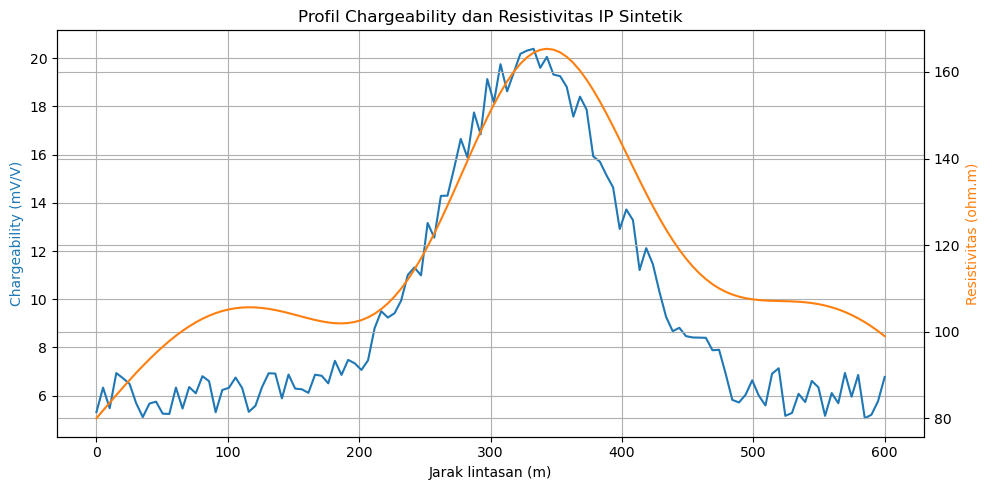

Interpretasi awal: zona chargeability relatif tinggi muncul di sekitar 250–410 m.
Zona ini hanya target untuk pemeriksaan lebih lanjut; bukan bukti langsung keberadaan bijih.


In [5]:
n_ip = 120
ip_x = np.linspace(0, 600, n_ip)
# Chargeability tinggi di zona tengah, resistivitas dibuat bervariasi.
chargeability = 5 + 2*np.random.rand(n_ip) + 14*np.exp(-((ip_x-330)/90)**2)
resistivity = 80 + 25*np.sin(ip_x/70) + 110*np.exp(-((ip_x-340)/100)**2)
ip_df = pd.DataFrame({
    "Jarak (m)": ip_x,
    "Chargeability (mV/V)": chargeability,
    "Resistivitas (ohm.m)": resistivity
})
# Ambang demonstrasi semata, bukan ambang universal untuk mineralisasi.
ip_df["Zona chargeability (demonstrasi)"] = np.where(
    ip_df["Chargeability (mV/V)"] >= 12, "Anomali relatif tinggi", "Latar belakang"
)
print("Ringkasan parameter IP:")
print(ip_df[["Chargeability (mV/V)", "Resistivitas (ohm.m)"]].describe().round(2).to_string())
print("\nJumlah titik per kategori (ambang demonstrasi 12 mV/V):")
print(ip_df["Zona chargeability (demonstrasi)"].value_counts().to_string())

fig, ax1 = plt.subplots()
ax1.plot(ip_x, chargeability, label="Chargeability (mV/V)", color="tab:blue")
ax1.set_xlabel("Jarak lintasan (m)")
ax1.set_ylabel("Chargeability (mV/V)", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(ip_x, resistivity, label="Resistivitas (ohm.m)", color="tab:orange")
ax2.set_ylabel("Resistivitas (ohm.m)", color="tab:orange")
ax1.set_title("Profil Chargeability dan Resistivitas IP Sintetik")
plt.tight_layout()
plt.show()

print("Interpretasi awal: zona chargeability relatif tinggi muncul di sekitar 250–410 m.")
print("Zona ini hanya target untuk pemeriksaan lebih lanjut; bukan bukti langsung keberadaan bijih.")


## **Prompt 4 — Analisis Data Ground Penetrating Radar (GPR)**

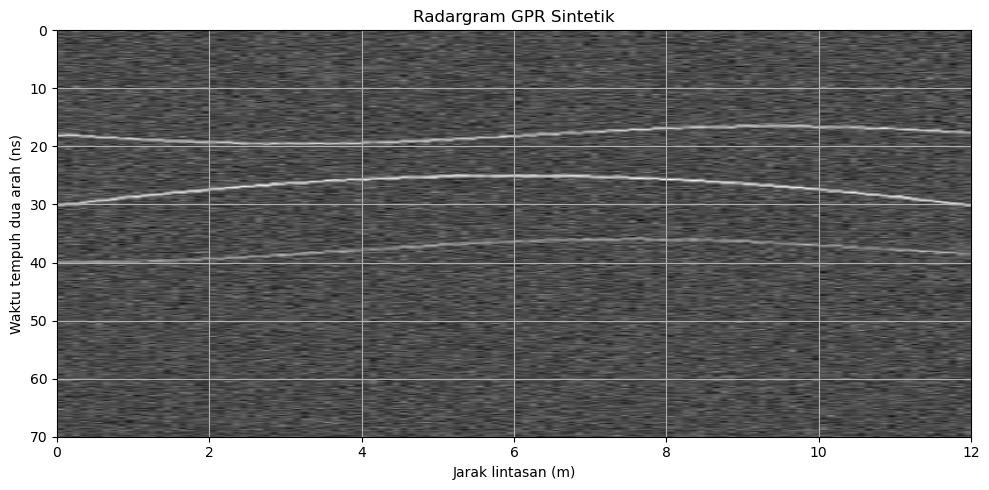

Estimasi kedalaman ilustratif (kecepatan asumsi 0,10 m/ns):
       Peristiwa  Waktu dua arah (ns)  Kecepatan asumsi (m/ns)  Kedalaman estimasi (m)
     Reflektor 1                   18                      0.1                    0.90
Puncak hiperbola                   25                      0.1                    1.25
     Reflektor 2                   38                      0.1                    1.90
Interpretasi awal: radargram menampilkan reflektor dan pola hiperbola sintetik.
Identitas objek tidak dapat ditentukan tanpa kalibrasi kecepatan dan validasi lapangan.


In [7]:
n_samples, n_gpr_traces = 350, 120
two_way_ns = np.linspace(0, 70, n_samples)
gpr_x = np.linspace(0, 12, n_gpr_traces)
gpr = np.random.normal(0, 0.12, (n_samples, n_gpr_traces))
# Reflektor datar dan hiperbola objek sintetik.
for j, x in enumerate(gpr_x):
    t1 = 18 + 1.5*np.sin(x/2)
    t2 = 38 + 2*np.cos(x/2.4)
    for center, amp in [(t1, 0.8), (t2, 0.55)]:
        idx = np.argmin(np.abs(two_way_ns-center))
        if 1 <= idx < n_samples-1:
            gpr[idx-1:idx+2, j] += amp*np.array([0.5, 1.0, 0.5])
# hiperbola sederhana di tengah lintasan
x0, t0 = 6.0, 25.0
for j, x in enumerate(gpr_x):
    t = np.sqrt(t0**2 + (2.8*(x-x0))**2)
    idx = np.argmin(np.abs(two_way_ns-t))
    if 1 <= idx < n_samples-1:
        gpr[idx-1:idx+2, j] += np.array([0.5, 1.0, 0.5])

fig, ax = plt.subplots()
ax.imshow(gpr, cmap="gray", aspect="auto",
          extent=[gpr_x.min(), gpr_x.max(), two_way_ns.max(), two_way_ns.min()])
ax.set(title="Radargram GPR Sintetik", xlabel="Jarak lintasan (m)",
       ylabel="Waktu tempuh dua arah (ns)")
plt.tight_layout()
plt.show()

# depth = v*t/2; gunakan kecepatan ilustratif 0.10 m/ns.
gpr_velocity_m_ns = 0.10
picked_time_ns = np.array([18, 25, 38])
gpr_depth_m = gpr_velocity_m_ns * picked_time_ns / 2
gpr_table = pd.DataFrame({
    "Peristiwa": ["Reflektor 1", "Puncak hiperbola", "Reflektor 2"],
    "Waktu dua arah (ns)": picked_time_ns,
    "Kecepatan asumsi (m/ns)": gpr_velocity_m_ns,
    "Kedalaman estimasi (m)": gpr_depth_m
})
print("Estimasi kedalaman ilustratif (kecepatan asumsi 0,10 m/ns):")
print(gpr_table.to_string(index=False))
print("Interpretasi awal: radargram menampilkan reflektor dan pola hiperbola sintetik.")
print("Identitas objek tidak dapat ditentukan tanpa kalibrasi kecepatan dan validasi lapangan.")

## **Prompt 5 — Analisis Data Electrical Resistivity Tomography (ERT)**

Rentang resistivitas model sintetik: 10.7–305.8 ohm.m
Median resistivitas model sintetik: 119.1 ohm.m


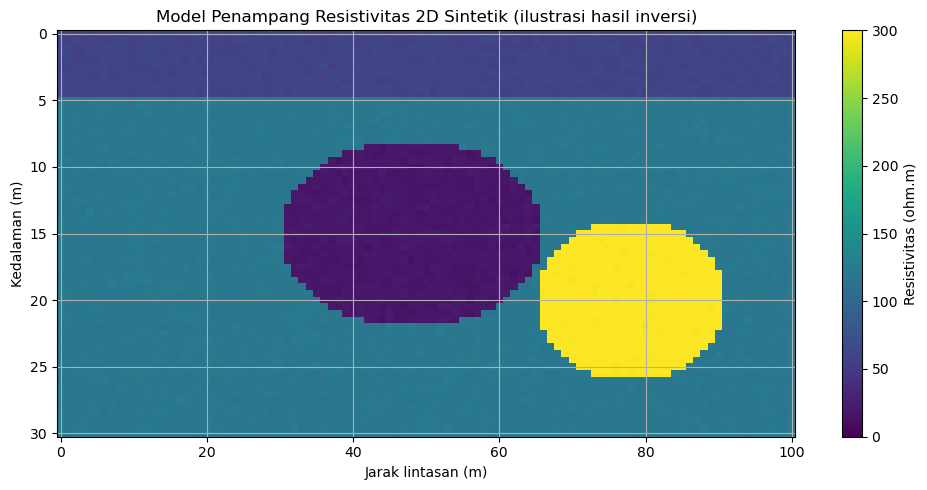

Zona resistivitas rendah (< 30 ohm.m): 781 sel model
Zona resistivitas tinggi (> 200 ohm.m): 483 sel model
Interpretasi awal: zona konduktif di bagian tengah dan zona resistif di kanan
ditanam ke dalam model sintetik. Pada data nyata, interpretasi perlu mempertimbangkan
kandungan air, porositas, litologi, kualitas data, dan hasil inversi.


In [8]:
ert_x = np.linspace(0, 100, 101)
ert_z = np.linspace(0, 30, 61)
EX, EZ = np.meshgrid(ert_x, ert_z)
# Model resistivitas sintetik: lapisan dangkal sedang, zona konduktif, dan batuan lebih resistif.
rho = 120*np.ones_like(EX)
rho[EZ < 5] = 60
conductive_zone = ((EX-48)/18)**2 + ((EZ-15)/7)**2 < 1
rho[conductive_zone] = 18
resistive_zone = ((EX-78)/13)**2 + ((EZ-20)/6)**2 < 1
rho[resistive_zone] = 300
rho += np.random.normal(0, 2, rho.shape)
rho = np.clip(rho, 5, None)

print(f"Rentang resistivitas model sintetik: {rho.min():.1f}–{rho.max():.1f} ohm.m")
print(f"Median resistivitas model sintetik: {np.median(rho):.1f} ohm.m")

fig, ax = plt.subplots()
mesh = ax.pcolormesh(EX, EZ, rho, shading="auto", cmap="viridis", vmin=0, vmax=300)
fig.colorbar(mesh, ax=ax, label="Resistivitas (ohm.m)")
ax.invert_yaxis()
ax.set(title="Model Penampang Resistivitas 2D Sintetik (ilustrasi hasil inversi)",
       xlabel="Jarak lintasan (m)", ylabel="Kedalaman (m)")
plt.tight_layout()
plt.show()

print("Zona resistivitas rendah (< 30 ohm.m):", int(np.sum(rho < 30)), "sel model")
print("Zona resistivitas tinggi (> 200 ohm.m):", int(np.sum(rho > 200)), "sel model")
print("Interpretasi awal: zona konduktif di bagian tengah dan zona resistif di kanan")
print("ditanam ke dalam model sintetik. Pada data nyata, interpretasi perlu mempertimbangkan")
print("kandungan air, porositas, litologi, kualitas data, dan hasil inversi.")

## **RINGKASAN AKHIR**

In [9]:
summary = pd.DataFrame([
    ["1. Seismik refleksi", "Reflektor dan diskontinuitas sintetik", "TWT, kecepatan, penampang"],
    ["2. Geomagnetik", "Anomali positif dan negatif sintetik", "Koordinat dan anomali (nT)"],
    ["3. IP", "Chargeability tinggi di bagian tengah lintasan", "Chargeability dan resistivitas"],
    ["4. GPR", "Reflektor dan hiperbola sintetik", "Waktu dua arah dan kecepatan asumsi"],
    ["5. ERT", "Zona resistivitas rendah dan tinggi", "Model resistivitas 2D (ohm.m)"],
], columns=["Metode", "Hasil demonstrasi", "Parameter utama"])
print(summary.to_string(index=False))
print("\nPENTING: seluruh grafik dan angka berasal dari data simulasi, bukan data lapangan.")


             Metode                              Hasil demonstrasi                     Parameter utama
1. Seismik refleksi          Reflektor dan diskontinuitas sintetik           TWT, kecepatan, penampang
     2. Geomagnetik           Anomali positif dan negatif sintetik          Koordinat dan anomali (nT)
              3. IP Chargeability tinggi di bagian tengah lintasan      Chargeability dan resistivitas
             4. GPR               Reflektor dan hiperbola sintetik Waktu dua arah dan kecepatan asumsi
             5. ERT            Zona resistivitas rendah dan tinggi       Model resistivitas 2D (ohm.m)

PENTING: seluruh grafik dan angka berasal dari data simulasi, bukan data lapangan.
